In [12]:
import nugget
import importlib
import torch

In [13]:
device='cuda:0'
geometry = nugget.geometries.DynamicString.DynamicString(
                device="cpu",
                hex_type='hexagonal',
                n_cjbs=20,  # Number of CJBs
                # random_xy=True,
                domain_size=1600,  # Size of detector domain
                dim=3,  # 3D geometry
                n_strings=70,  # Initial number of detector strings
                points_per_string=20,  # Number of PMTs/sensors per string
                # custom_string_spacing=50  # Custom spacing between strings
                custom_z_spacing=50,
                random_assignment_logits=True,
                assignment_logits_init=1,
                assignment_logits_std=2,
                assignment_activation='softmax',
                cjb_weight_gate='probability',  
            ) # Initialize the dynamic string geometry object

visualizer = nugget.utils.vis_tools.Visualizer(
    device=device,
    dim=3, 
    domain_size=1400,
    # gif_temp_dir='./gif_temp_3',  # Directory for storing animation frames
    ) # Initialize the visualizer for live visualization of the geometry and optimization process

In [14]:
# using here the hybrid optimizer which allows for the use of both JAX and PyTorch for optimization
optimizer = nugget.utils.basic_optimizer.Optimizer(
    device=geometry.device, 
    geometry=geometry,
    visualizer=visualizer,
    # conflict_free=False,  # Single-objective optimization (vs multi-objective)
    use_alm=True,  # Use Augmented Lagrangian Method for constraints
    sigmoid_losses=True,
)
# initialize optimizer and create the initial geometry, specifying which parameters to optimize and their learning rates
optimizer.init_geometry(
    # opt_list=[('string_weights', 0.5)],  # Learning rate for string weights (without sigmoid applied)
    opt_list=[('cjb_xy', 10), ('assignment_logits', 0.1)],  # Learning rates for string xy positions
)

Optimizing cjb_xy with torch.Size([20, 2]) shape
Optimizing assignment_logits with torch.Size([70, 20]) shape


In [15]:
importlib.reload(nugget.losses.geometry_penalties)
importlib.reload(nugget.losses.cost_loss)

# Local String Repulsion: Prevents strings from getting too close to each other
local_string_repulsion_penalty = nugget.losses.geometry_penalties.LocalStringRepulsionPenalty(
    device=geometry.device
)

cost_loss = nugget.losses.cost_loss.CostLoss(
    device=geometry.device,
    C_cable=200.0,  # Cost per unit length of cable
    C_cjb=150e3,  # Cost per CJB
    C_connection=20e3,  # Cost per connection
)

cjb_capacity_penalty = nugget.losses.geometry_penalties.CJBCapacityPenalty(
    device=geometry.device,
    cjb_capacity=8,  # Maximum number of strings per CJB
)

string_connection_penalty = nugget.losses.geometry_penalties.StringConnectionPenalty(
    device=geometry.device,
)

cjb_connection_binarization_penalty = nugget.losses.geometry_penalties.CJBConnectionBinarizationPenalty(
    device=geometry.device,
)
# # String Boundary Penalty: Keeps strings within the detector domain
# string_boundary_penalty = nugget.losses.geometry_penalties.StringBoundaryPenaltyCircle(
#     device=geometry.device,
# )

# # String Number Penalty: Penalizes having too many active strings
# string_number_penalty = nugget.losses.geometry_penalties.StringNumberPenalty(
#     device=geometry.device
# )

# # Weight Binarization: Encourages string weights to be either 0 or 1
# weighted_binarization_penalty = nugget.losses.geometry_penalties.WeightBinarizationPenalty(
#     device=geometry.device
# )


# ROV Penalty: Accounts for physical constraints from Remotely Operated Vehicle
rov_penalty = nugget.losses.geometry_penalties.ROVPenalty(
    device=geometry.device, 
    rov_rec_width=230,  # ROV dimensions
    rov_height=160, 
    rov_tri_length=160
)

In [16]:
# set up loss function dictionary, parameters, weights, and sigmoid list for optimization

loss_func_dict = {
    'local_string_repulsion_penalty': local_string_repulsion_penalty, 
    # 'rov_penalty': rov_penalty,                                       
    'cjb_capacity_penalty': cjb_capacity_penalty,                                      
    # 'string_connection_penalty': string_connection_penalty, 
    'cost_loss': cost_loss,
    # 'cjb_connection_binarization_penalty': cjb_connection_binarization_penalty,                                    
}

loss_params = {

    # 'boundary_range': 1200,  # Size of boundary region
    # 'eva_min_num_strings': 72,  # Minimum number of active strings
    'max_radius': 80,  # Maximum radius for string repulsion penalty
    'num_angles': 360,  # Number of angles (divided into 360 degrees) to test for rov
    'rov_alt_mode': True,  # Whether to use alternative mode for rov penalty (see rov_penalty.py for details)
    'local_sharpness': 10,  # Sharpness parameter for local string repulsion
    # 'boundary_sharpness': 10,  # Sharpness parameter for boundary penalty
    # 'string_number_beta':5,
   
    'rov_soft_inside':True, # ROV penalty parameters
    'rov_inside_sharpness': 5,
    'rov_angle_softmin_tau': 0.05,
    'rov_angle_chunk_size': 360,
    'rov_inside_use_softplus': True,
     # 'detach_other_probs':False,
 
    'constraints_list': [ 
                'rov_penalty', 
                # 'string_boundary_penalty', 
                'local_string_repulsion_penalty', 
                'cjb_capacity_penalty',
                'string_connection_penalty',
                # 'cjb_connection_binarization_penalty',
                # 'string_number_penalty', 
                # 'string_weights_penalty',
                # 'weight_binarization_penalty',
                ],  # Constraints to enforce with ALM
}   

loss_weights_dict = {
    'cjb_capacity_penalty': 100,  # Limit number of strings per CJB
    'string_connection_penalty': 0.01,  # Limit number of connections per string
    'cost_loss': 0.1,  # Cost loss weight
    'string_boundary_penalty': 2,  # Very high: hard constraint
    'local_string_repulsion_penalty': 1,
    'cjb_connection_binarization_penalty': 1,
    'string_weights_penalty': 0.05,     # Encourage sparse solutions
    'string_number_penalty': 10,      # Limit detector complexity
    'weight_binarization_penalty': 0.1,
    'rov_penalty': 1,
} # weights for each loss function, used in the optimization process (before applying ALM and sigmoid)

# List of loss functions that should use sigmoid activation before being applied, helps with loss balancing and scaling
loss_sigmoid_list = [
    'string_boundary_penalty',  
    # 'local_string_repulsion_penalty',
    'string_weights_penalty',     
    'string_number_penalty',      
    'weight_binarization_penalty',
    'rov_penalty',
    # 'cjb_capacity_penalty',
    # 'string_connection_penalty',
    # 'cost_loss'
]


In [17]:
# Stop optimization when every string's strongest assignment passes this cutoff.
assignment_cutoff = 0.86

def all_strings_pass_assignment_cutoff(current_geom):
    assignment_weights = current_geom["assignment_weights"]
    best_weights = assignment_weights.max(dim=1).values
    return bool(torch.all(best_weights >= assignment_cutoff).item())

In [18]:
# specify which plots to generate live and their settings

plot_types = [
    'loss_components',           # Loss function values over time
    # 'uw_loss_components',        # Unweighted loss components
    # 'string_weights_scatter',    # String weight visualization
    'string_xy',
    # 'angular_resolution',
    # 'energy_resolution',
    'string_xy_rov_penalty',
    'string_xy_local_string_repulsion_penalty',
    'cost_history',
    # 'string_history',
    # 'nn_distance_history',
    # 'alm_mu',
    'alm_lambda',
]

vis_kwargs = {
    # 'moving_average_window': 10,  # Window size for smoothing loss curves
    # 'moving_average_losses': ['angular_resolution_loss', 'rov_penalty'],  # Losses to smooth
    'plot_types': plot_types,
    'gif_plot_selection': plot_types,  # Which plots to include in animation
    # 'loss_filter': ['string_boundary_penalty'],  # Hide large loss components from loss component plot
    # 'zoom_range':800,
    # 'max_radius': loss_params['boundary_range']/2,
    'string_xy_show_cjbs':True,
    'show_cjb_connections':True,
    'rov_penalty_func': rov_penalty,
    'use_relative_energy': True,
    'plot_geom_contour_only': True,
    'resolution_logy_angular': True,
    'rov_draw_safe_space_union': True,
    'rov_union_per_space_colors':True,
    'rov_draw_safe_space_on_violations':False,
    # 'rov_safe_space_one_fold_only': True,
    'resolution_stat': 'mean',  # Statistic to plot for resolution ('median', 'mean', or 'fom')
}

In [19]:
# loss_dict=optimizer.loss_dict         # resupply loss histories if continuing optimization (only for visualization)
# uw_loss_dict=optimizer.uw_loss_dict  
# vis_loss_dict=optimizer.vis_loss_dict
# vis_uw_loss_dict=optimizer.vis_uw_loss_dict

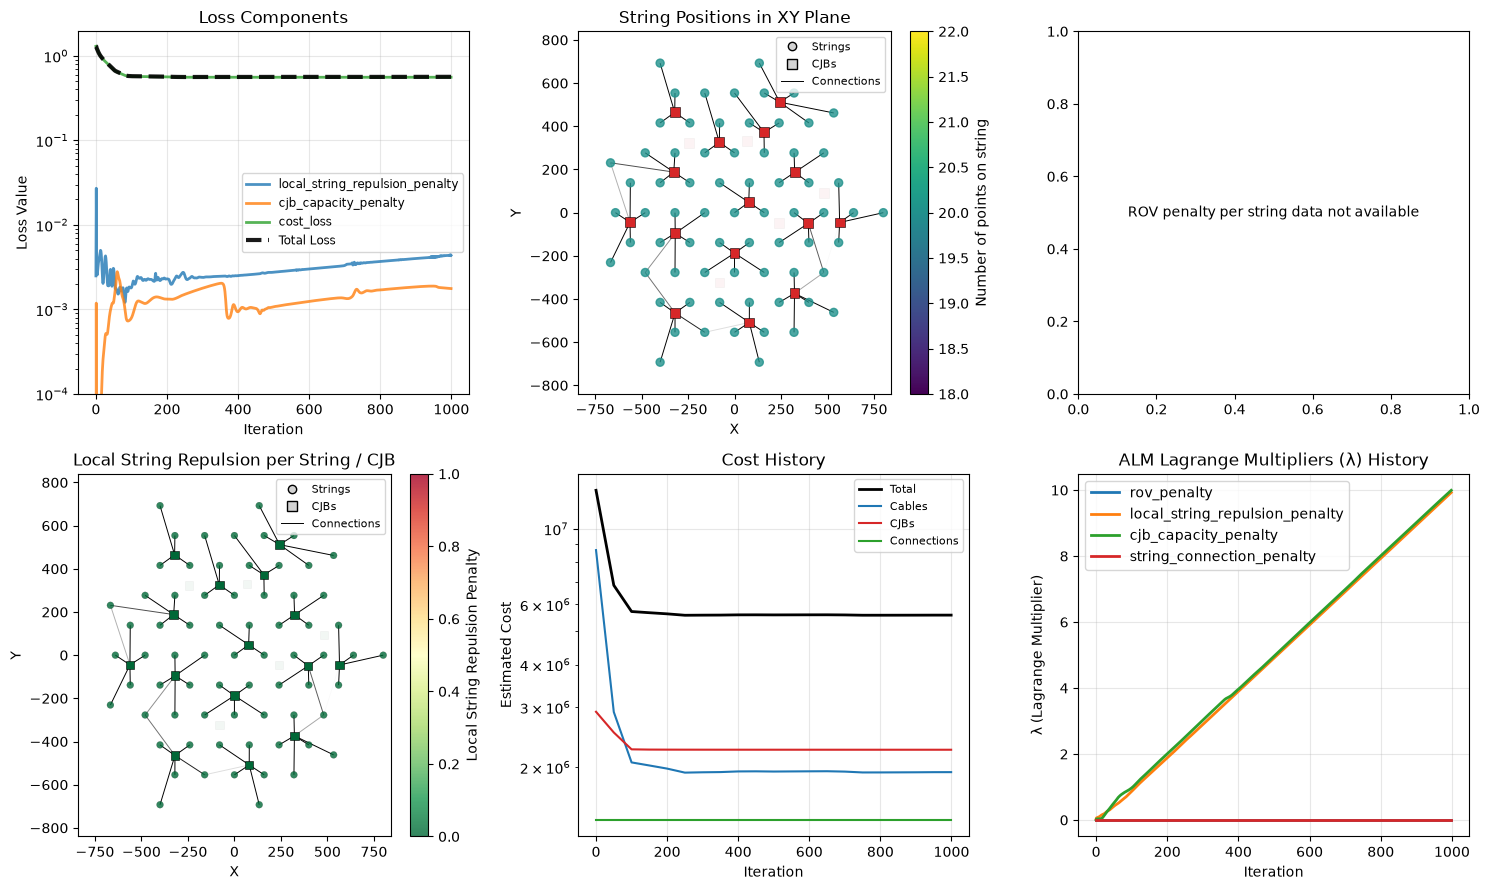

Saved GIF frame 21 to /tmp/gif_frames_7rszb96b/frame_10519.png
Iter 1000/1000, Total Loss: 0.5646 | local_string_repulsion_penalty: 0.0044 | cjb_capacity_penalty: 0.0018 | cost_loss: 0.5584
No hard-assignment estimate: not all strings met the cutoff before the iteration limit.


In [20]:
# Begin optimization process, combining all the configurations

# optimizer.visualizer.cleanup_gif_temp_files()
geom_dict = optimizer.optimize(
    # clear_cuda_cache=True,                 # Clear torch GPU memory cache between iterations
    loss_func_dict=loss_func_dict,          # Dictionary of loss functions to use
    loss_weights_dict=loss_weights_dict,    # Weights for combining multiple losses
    loss_params_dict=loss_params,           # Parameters for loss function computation
    n_iter=1000,                           # Maximum number of optimization iterations
    vis_kwargs=vis_kwargs,                  # Visualization parameters
    print_freq=50,                          # Print progress every N iterations
    vis_freq=100,                           # Create plots every N iterations
    gif_freq=50,                            # Save animation frames every N iterations
    sigmoid_loss_list=loss_sigmoid_list,         # Which losses to apply sigmoid to (for better optimization dynamics)
    revert_on_nan=True,                     # Revert geometry if loss becomes NaN
    max_nan_retries=10,                     # Maximum number of consecutive NaN reverts before stopping
    # save_geom_folder='./cjb_hex_test_no_rov',  # Directory to save geometry checkpoints
    # save_geom_freq=100,                      # Save geometry every N iterations
    # continue_saving=False,
    # save_best_geom_file = './best_geom_1_event.pkl',  # File to save best geometry found
    # save_last_geom = False,
    # loss_dict=loss_dict,         # resupply loss histories if continuing optimization (only for visualization)
    # uw_loss_dict=uw_loss_dict,
    # vis_loss_dict=vis_loss_dict,
    # vis_uw_loss_dict=vis_uw_loss_dict,
    stop_condition=all_strings_pass_assignment_cutoff,
)

#final_assignment_weights = geom_dict["assignment_weights"].detach().cpu()
#print("Final assignment weight matrix (rows=strings, columns=CJBs):")
#print("String | " + " ".join(f"{cjb_idx:>7}" for cjb_idx in range(final_assignment_weights.shape[1])))
#for string_idx, weights in enumerate(final_assignment_weights.tolist()):
#   print(f"{string_idx:>6} | " + " ".join(f"{weight:7.4f}" for weight in weights))

if all_strings_pass_assignment_cutoff(geom_dict):
    with torch.no_grad():
        string_xy = geom_dict["string_xy"]
        cjb_xy = geom_dict["cjb_xy"]
        assignment_weights = geom_dict["assignment_weights"]
        best_weights, best_cjb_indices = assignment_weights.max(dim=1)
        connected_mask = best_weights >= assignment_cutoff
        connected_string_indices = torch.arange(string_xy.shape[0], device=string_xy.device)[connected_mask]
        connected_cjb_indices = best_cjb_indices[connected_mask]
        cable_lengths = torch.linalg.vector_norm(
            string_xy[connected_string_indices] - cjb_xy[connected_cjb_indices], dim=1
        )
        active_cjb_count = torch.unique(connected_cjb_indices).numel()
        quick_cable_cost = cost_loss.parameters["C_cable"] * cable_lengths.sum()
        quick_cjb_cost = cost_loss.parameters["C_cjb"] * active_cjb_count
        quick_connection_cost = cost_loss.parameters["C_connection"] * connected_string_indices.numel()
        quick_total_physical_cost = quick_cable_cost + quick_cjb_cost + quick_connection_cost

    print(f"Quick hard-assignment estimate (cutoff={assignment_cutoff:.2f}):")
    print(f"  Connected strings: {connected_string_indices.numel()}/{string_xy.shape[0]}")
    print(f"  Active CJBs: {active_cjb_count}/{cjb_xy.shape[0]}")
    print(f"  Cable cost: {quick_cable_cost.item():,.2f}")
    print(f"  CJB cost: {quick_cjb_cost:,.2f}")
    print(f"  Connection cost: {quick_connection_cost:,.2f}")
    print(f"  Total physical cost: {quick_total_physical_cost.item():,.2f}")
    print(f" Total Cable Length: {cable_lengths.sum().item():,.2f}")
else:
    print("No hard-assignment estimate: not all strings met the cutoff before the iteration limit.")


Assignment cutoff: 0.8600
Weakest string-CJB connection: string 51 -> CJB 15
Strongest assignment weight: 0.558879
Cutoff shortfall: 0.301121
Strings below cutoff: [51, 59, 65]


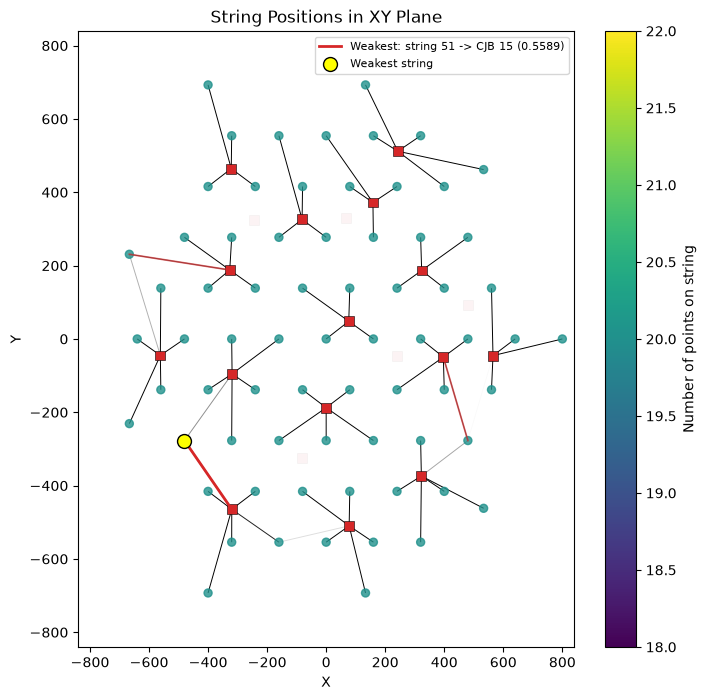

In [24]:
import matplotlib.pyplot as plt

with torch.no_grad():
    assignment_weights = geom_dict["assignment_weights"]
    best_weights, best_cjb_indices = assignment_weights.max(dim=1)
    failed_mask = best_weights < assignment_cutoff
    failed_string_indices = torch.arange(best_weights.shape[0], device=best_weights.device)[failed_mask]

if failed_string_indices.numel() == 0:
    print(f"All string-CJB assignments meet the cutoff of {assignment_cutoff:.4f}; no failure plot needed.")
else:
    string_xy = geom_dict["string_xy"]
    cjb_xy = geom_dict["cjb_xy"]
    cjb_weights = geom_dict.get("cjb_weights", None)
    assignment_weights = geom_dict["assignment_weights"]

    weights_cpu = best_weights.detach().cpu()
    cjb_indices_cpu = best_cjb_indices.detach().cpu()
    failed_indices_cpu = failed_string_indices.detach().cpu()

    weakest_index = int(failed_indices_cpu[weights_cpu[failed_indices_cpu].argmin()].item())
    weakest_cjb_index = int(cjb_indices_cpu[weakest_index].item())
    weakest_weight = float(weights_cpu[weakest_index].item())

    print(f"Assignment cutoff: {assignment_cutoff:.4f}")
    print(f"Weakest string-CJB connection: string {weakest_index} -> CJB {weakest_cjb_index}")
    print(f"Strongest assignment weight: {weakest_weight:.6f}")
    print(f"Cutoff shortfall: {assignment_cutoff - weakest_weight:.6f}")
    print(f"Strings below cutoff: {failed_indices_cpu.tolist()}")

    fig, ax = plt.subplots(figsize=(8, 8))
    visualizer._create_plot(
        plot_type="string_xy",
        ax=ax,
        fig=fig,
        iteration=0,
        points=geom_dict["points_3d"],
        string_xy=string_xy,
        cjb_xy=cjb_xy,
        cjb_weights=cjb_weights,
        assignment_weights=assignment_weights,
        points_per_string_list=geom_dict.get("points_per_string_list", None),
        string_indices=geom_dict.get("string_indices", None),
        string_xy_show_cjbs=vis_kwargs.get("string_xy_show_cjbs", True),
        show_cjb_connections=vis_kwargs.get("show_cjb_connections", True),
        zoom_range=vis_kwargs.get("zoom_range", None),
        weight_threshold=vis_kwargs.get("weight_threshold", 0.7),
    )

    string_xy_cpu = string_xy.detach().cpu()

    for string_index in failed_indices_cpu.tolist():
        cjb_index = int(cjb_indices_cpu[string_index].item())
        ax.plot(
            [string_xy_cpu[string_index, 0], cjb_xy.detach().cpu()[cjb_index, 0]],
            [string_xy_cpu[string_index, 1], cjb_xy.detach().cpu()[cjb_index, 1]],
            color="tab:red",
            linewidth=1.3,
            alpha=0.65,
            zorder=4,
        )

    ax.plot(
        [string_xy_cpu[weakest_index, 0], cjb_xy.detach().cpu()[weakest_cjb_index, 0]],
        [string_xy_cpu[weakest_index, 1], cjb_xy.detach().cpu()[weakest_cjb_index, 1]],
        color="tab:red",
        linewidth=2.0,
        alpha=1.0,
        zorder=5,
        label=f"Weakest: string {weakest_index} -> CJB {weakest_cjb_index} ({weakest_weight:.4f})",
    )
    ax.scatter(
        [string_xy_cpu[weakest_index, 0]],
        [string_xy_cpu[weakest_index, 1]],
        s=100,
        c="yellow",
        edgecolor="black",
        zorder=6,
        label="Weakest string",
    )
    ax.legend(loc="upper right", fontsize=8, framealpha=0.8)
    plt.show()


In [22]:
# optimizer.visualizer.finalize_gif(
#     gif_filename='../gifs/opt_test_cjb_hex.gif',  # Output filename
#     gif_fps=10,                    # Animation frame rate
#     cleanup_images=False           # Keep individual frames for debugging
# )